# 02 · Slang

Part 2 of the claim: *the vibe isn't in the words people search with.*

1. Gap table: reviews rarely use the slang people search with.
2. Which slang dictionary knows our query words?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from vibecheck.filter_sf import REVIEWS_OUT
from vibecheck.lexicon import GAP_QUERIES, UD_CSV, best_definitions, gap_table, load_ud_definitions
from vibecheck.plots import MUTED, use_style
from vibecheck.report import write_section
from vibecheck.wiktionary import WIKTIONARY_OUT, build_wiktionary_slang

use_style()
reviews = pd.read_parquet(REVIEWS_OUT)

## 1. Gap table

How many places a keyword search can reach with the slang word vs. its plain meaning.
Words picked before counting. Every row is shown.

In [2]:
gap = gap_table(reviews)
gap

,query,plain meaning,reviews (slang),reviews (plain),places (slang),places (plain)
0,boujee,"fancy, upscale, classy, elegant, luxurious",32,1582,32,1154
1,lowkey,"low-key, low key, laid-back, unpretentious, un...",14,548,14,478
2,vibey,"atmosphere, ambiance, ambience",763,10919,628,3530
3,aesthetic,"beautiful, gorgeous, stylish, decor",93,4171,91,2236
4,chill,"relaxed, relaxing, calm, mellow, laid-back",1418,1365,965,1035
5,bussin,"delicious, tasty, flavorful",5,31683,5,4949
6,slaps,"delicious, tasty, flavorful",24,31683,23,4949
7,goated,"the best, excellent, outstanding",0,22461,0,4969
8,poppin,"lively, bustling, busy, packed",29,4045,27,2539
9,instagrammable,"photogenic, picturesque",11,20,10,19


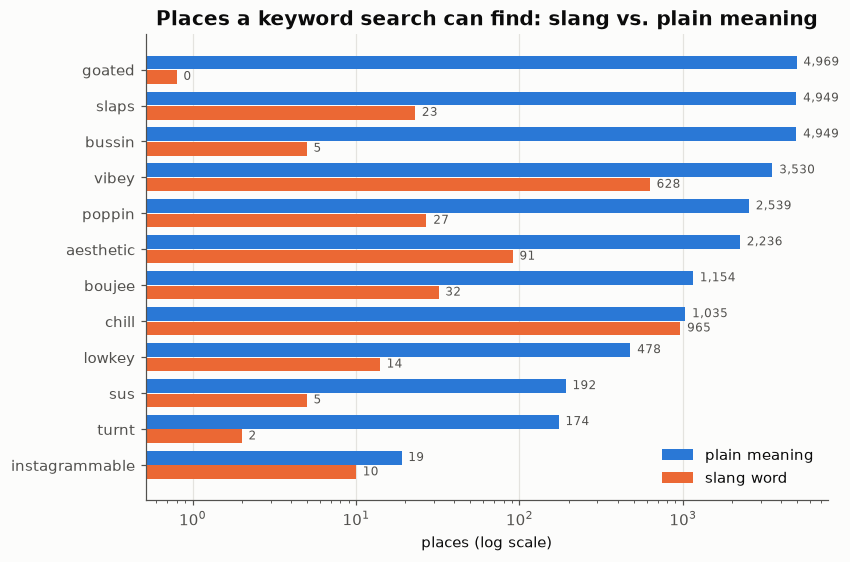

In [3]:
SLANG_COLOR, PLAIN_COLOR = "#eb6834", "#2a78d6"
order = gap.sort_values("places (plain)")
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(y + 0.2, order["places (plain)"].clip(lower=0.8), height=0.38, color=PLAIN_COLOR, label="plain meaning")
ax.barh(y - 0.2, order["places (slang)"].clip(lower=0.8), height=0.38, color=SLANG_COLOR, label="slang word")
for i, (s, p) in enumerate(zip(order["places (slang)"], order["places (plain)"], strict=True)):
    ax.text(max(s, 0.8) * 1.1, i - 0.2, f"{s:,}", va="center", color=MUTED, fontsize=8)
    ax.text(p * 1.1, i + 0.2, f"{p:,}", va="center", color=MUTED, fontsize=8)
ax.set_yticks(y, order["query"])
ax.set_xscale("log")
ax.set(title="Places a keyword search can find: slang vs. plain meaning", xlabel="places (log scale)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.savefig("../reports/gap_chart.png")
plt.show()

## 2. Which dictionary knows our query words?

To expand a query we need the slang word's meaning. Two sources:

- **Urban Dictionary** dump: 2.6M definitions, votes stop in 2016. We use the top-voted definition.
- **Wiktionary** (kaikki.org extract, 2026): only senses tagged slang, informal or colloquial,
  minus ones tagged offensive.

In [4]:
ud = best_definitions(load_ud_definitions(UD_CSV), GAP_QUERIES)
wiki = pd.read_parquet(WIKTIONARY_OUT) if WIKTIONARY_OUT.exists() else build_wiktionary_slang()
wiki_first = wiki.drop_duplicates("term").set_index("term")["gloss"].reindex(list(GAP_QUERIES))

either = (ud.notna() | wiki_first.notna()).sum()
print(f"Urban Dictionary knows {ud.notna().sum()}/{len(ud)}, Wiktionary {wiki_first.notna().sum()}/{len(ud)}, "
      f"together {either}/{len(ud)}")
meanings = pd.DataFrame({"Urban Dictionary (2016)": ud.str.slice(0, 90), "Wiktionary (2026)": wiki_first.str.slice(0, 90)})
meanings = meanings.fillna("—")
meanings

Urban Dictionary knows 7/12, Wiktionary 10/12, together 12/12


,Urban Dictionary (2016),Wiktionary (2026)
term,,
boujee,—,Behaving like or pertaining to people of a hig...
lowkey,To keep things secret,In a low-key or surreptitious manner; secretiv...
vibey,—,Having a vibe; atmospheric and trendy.
aesthetic,ADJECTIVE: 1. Beautiful. 2. Sensitive to o...,—
chill,"1. to calm down 2. cool, tight, wicked, sick...","Calm, relaxed, easygoing."
bussin,—,Delicious.
slaps,crackin songs from the bay area,Makeup; cosmetics.
goated,—,Being or considered the greatest of all time; ...
poppin,to get (something) started,—


**What this shows**

- Wiktionary knows 10 of 12, Urban Dictionary 7 of 12. Together they cover all 12, so query expansion
  uses Wiktionary first and falls back to Urban Dictionary.
- Neither picks the right sense by itself. Wiktionary's first sense of "slaps" is "makeup", and Urban
  Dictionary's "lowkey" is "to keep things secret". The engine has to pick the sense that fits the query.

## 3. Save to `numbers.md`

In [5]:
missing_ud = ", ".join(ud.index[ud.isna()])
missing_wiki = ", ".join(wiki_first.index[wiki_first.isna()]) or "none"
md = f"""## Slang: the vibe is not in the words people search with (notebook 02)

Words picked before counting. All rows shown.

{gap.to_markdown(index=False)}

Which dictionary knows our {len(ud)} query words?

- Urban Dictionary dump (2016): {ud.notna().sum()}/{len(ud)}. Missing: {missing_ud}.
- Wiktionary (2026, {wiki['term'].nunique():,} slang terms): {wiki_first.notna().sum()}/{len(ud)}. Missing: {missing_wiki}.
- Together: {either}/{len(ud)}. First senses are often wrong ("slaps" = makeup), so pick the sense that fits the query.

{meanings.to_markdown()}
"""
write_section("slang", md)
print(md)

## Slang: the vibe is not in the words people search with (notebook 02)

Words picked before counting. All rows shown.

| query          | plain meaning                                           |   reviews (slang) |   reviews (plain) |   places (slang) |   places (plain) |
|:---------------|:--------------------------------------------------------|------------------:|------------------:|-----------------:|-----------------:|
| boujee         | fancy, upscale, classy, elegant, luxurious              |                32 |              1582 |               32 |             1154 |
| lowkey         | low-key, low key, laid-back, unpretentious, understated |                14 |               548 |               14 |              478 |
| vibey          | atmosphere, ambiance, ambience                          |               763 |             10919 |              628 |             3530 |
| aesthetic      | beautiful, gorgeous, stylish, decor                     |                93 |         